### Data

Prepared input: [data/task1/fundamentals.csv](./data/task1/fundamentals.csv), P&G and six peers. Prices: **16 October 2026**. Financials: **12 months ended 30 June 2026**, USD. Collection date: 19 October. Offline analysis; no data downloads.

Sources: [Yahoo Finance](https://finance.yahoo.com/quote/PG/financials/), missing CHD figures from [SEC](https://data.sec.gov/api/xbrl/companyfacts/CIK0000313927.json), CLX EPS from [Clorox](https://investors.thecloroxcompany.com/news/news-details/2026/Clorox-Reports-Q4-and-FY26-Results-Provides-FY27-Outlook/default.aspx). FCF = operating cash flow minus capital expenditure.

### Companies and peer selection

- **[P&G (PG)](https://us.pg.com/annualreport2026/financial-highlights/):** household cleaning, laundry, baby care, beauty and grooming.
- **[Colgate-Palmolive (CL)](https://www.colgatepalmolive.com/en-us/who-we-are):** oral, personal and home care, plus pet nutrition.
- **[Kimberly-Clark (KMB)](https://www.kimberly-clark.com/en-us/brands):** diapers, tissues and hygiene products.
- **[Church & Dwight (CHD)](https://churchdwight.com/our-brands/consumer-brands/):** laundry, household cleaning, oral and personal care.
- **[Clorox (CLX)](https://www.thecloroxcompany.com/brands/):** cleaning, disinfecting and other household products.
- **[Edgewell (EPC)](https://edgewell.com/pages/our-brands):** shaving, grooming and sun-care products.
- **[Coty (COTY)](https://www.coty.com/our-brands):** fragrances, cosmetics and beauty products.

Selection: product overlap with P&G and USD prices/reporting. Different company sizes and product mixes, especially EPC and COTY; peer-removal sensitivity below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

TARGET = "PG"
PEERS = ["CL", "KMB", "CHD", "CLX", "EPC", "COTY"]
folder = Path(".") if Path("data/task1/fundamentals.csv").exists() else Path("Assignment2")
data = pd.read_csv(folder / "data/task1/fundamentals.csv", index_col="ticker")

### Ratios

EPS = earnings per share; negative EPS = loss. EPC and COTY: negative P/E shown, excluded from the main P/E median ([course notes](https://github.com/jmichankow/aais_2627/blob/main/lessons/lesson02_longshort_valuation.md#4-relative-valuation-multiples)); included in the other three medians.

In [2]:
# Calculate valuation ratios.
data["market_cap"] = data["price"] * data["shares"]
data["ev"] = data["market_cap"] + data["debt"] + data["preferred"] + data["minority"] - data["cash"]
data["fcf_ttm"] = data["ocf_ttm"] - data["capex_ttm"]
data["P/E"] = data["price"] / data["eps_ttm"].where(data["eps_ttm"] != 0)
data["EV/EBITDA"] = data["ev"] / data["ebitda_ttm"].where(data["ebitda_ttm"] > 0)
data["P/B"] = data["market_cap"] / data["book_equity"].where(data["book_equity"] > 0)
data["FCF yield (%)"] = 100 * data["fcf_ttm"] / data["market_cap"]
metrics = ["P/E", "EV/EBITDA", "P/B", "FCF yield (%)"]
stock = data.loc[TARGET]
assert TARGET not in PEERS and 5 <= len(set(PEERS)) == len(PEERS) <= 7
print("Share price, earnings per share and valuation ratios:")
display(data.loc[[TARGET] + PEERS, ["price", "eps_ttm"] + metrics].rename(columns={"price": "Price ($)", "eps_ttm": "EPS ($)"}).round(2).fillna("N/A"))

Share price, earnings per share and valuation ratios:


,Price ($),EPS ($),P/E,EV/EBITDA,P/B,FCF yield (%)
ticker,,,,,,
PG,159.35,6.62,24.07,16.24,6.95,4.09
CL,94.11,2.52,37.35,21.32,317.89,5.14
KMB,105.57,5.88,17.95,12.73,20.02,5.19
CHD,104.53,3.11,33.61,20.51,5.70,4.50
CLX,87.09,4.82,18.07,13.76,117.03,3.85
EPC,27.91,-2.01,-13.89,25.01,0.88,4.07
COTY,3.20,-0.70,-4.57,87.64,0.94,12.36


### Peer-median valuation

P&G share-price estimates from peer medians. Gap = estimated price / market price - 1.

In [3]:
# Calculate peer medians.
def valuations(peers):
    ratios = data.loc[peers, metrics]
    # Use positive ratios only.
    medians = ratios.where(ratios > 0).median()
    values = pd.Series({
        "P/E": medians["P/E"] * stock["eps_ttm"],
        "EV/EBITDA": (medians["EV/EBITDA"] * stock["ebitda_ttm"] - stock["debt"]
                       + stock["cash"] - stock["preferred"] - stock["minority"]) / stock["shares"],
        "P/B": medians["P/B"] * stock["book_equity"] / stock["shares"],
        "FCF yield (%)": stock["fcf_ttm"] / (medians["FCF yield (%)"] / 100) / stock["shares"],
    })
    denominators = pd.Series([stock["eps_ttm"], stock["ebitda_ttm"], stock["book_equity"], stock["fcf_ttm"]], index=metrics)
    return medians, values.where(denominators > 0)

medians, implied = valuations(PEERS)
result = pd.DataFrame({"Peer median": medians, "Implied price ($)": implied,
                       "Gap (%)": 100 * (implied / stock["price"] - 1)})
result["Valid peers"] = data.loc[PEERS, metrics].where(data.loc[PEERS, metrics] > 0).count()
print("Peer-median valuation:")
display(result.round(2))

Peer-median valuation:


,Peer median,Implied price ($),Gap (%),Valid peers
P/E,25.84,171.06,7.35,4
EV/EBITDA,20.91,208.44,30.81,6
P/B,12.86,295.11,85.19,6
FCF yield (%),4.82,135.19,-15.16,6


### P/E: including or excluding losses

Comparison of P/E medians: profitable peers versus all peers.

In [4]:
# Compare both P/E medians.
pe_all = data.loc[PEERS, "P/E"].median()
pe_comparison = pd.DataFrame({
    "Peers used": [int((data.loc[PEERS, "eps_ttm"] > 0).sum()), int(data.loc[PEERS, "P/E"].count())],
    "Median P/E": [medians["P/E"], pe_all],
    "Implied price ($)": [implied["P/E"], pe_all * stock["eps_ttm"]],
}, index=["Positive earnings only", "Including loss-making peers"])
pe_comparison["Gap (%)"] = 100 * (pe_comparison["Implied price ($)"] / stock["price"] - 1)
display(pe_comparison.round(2))

,Peers used,Median P/E,Implied price ($),Gap (%)
Positive earnings only,4,25.84,171.06,7.35
Including loss-making peers,6,18.01,119.23,-25.17


### Investment call

Overall estimate: median of four implied prices. Simple combination, without adjustments for method reliability.

In [5]:
# Combine the four valuations.
fair_value = implied.median()
assert pd.notna(fair_value), "No valid target valuation"
call = "LONG" if fair_value > stock["price"] else "SHORT"
print(f"{TARGET}: market ${stock['price']:.2f}, implied ${fair_value:.2f}, "
      f"gap {100 * (fair_value / stock['price'] - 1):+.1f}%, {call}")
print(f"P/E + EV/EBITDA average: ${implied[['P/E', 'EV/EBITDA']].mean():.2f}")

PG: market $159.35, implied $189.75, gap +19.1%, LONG
P/E + EV/EBITDA average: $189.75


### Peer-selection sensitivity

Valuation repeated without each peer in turn; five peers per test.

In [6]:
# Recalculate without each peer.
changes = []
for excluded in PEERS:
    _, prices = valuations([ticker for ticker in PEERS if ticker != excluded])
    estimate = prices.median()
    changes.append({"Excluded": excluded, "Implied price ($)": estimate,
                    "Gap (%)": 100 * (estimate / stock["price"] - 1),
                    "Call": "LONG" if estimate > stock["price"] else "SHORT"})
print("Peer-selection sensitivity:")
sensitivity = pd.DataFrame(changes).set_index("Excluded")
display(sensitivity.round(2))

Peer-selection sensitivity:


,Implied price ($),Gap (%),Call
Excluded,,,
CL,137.85,-13.49,SHORT
KMB,178.78,12.19,LONG
CHD,169.70,6.49,LONG
CLX,171.76,7.78,LONG
EPC,187.63,17.75,LONG
COTY,187.63,17.75,LONG


### Valuation comparison

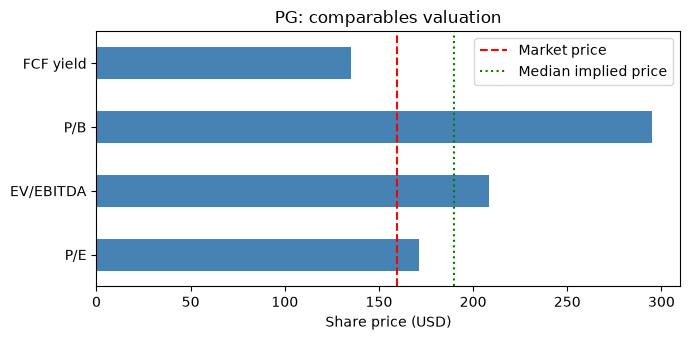

In [7]:
# Plot implied and market prices.
implied.rename(index={"FCF yield (%)": "FCF yield"}).plot.barh(figsize=(7, 3.5), color="steelblue")
plt.axvline(stock["price"], color="red", linestyle="--", label="Market price")
plt.axvline(fair_value, color="green", linestyle=":", label="Median implied price")
plt.title(f"{TARGET}: comparables valuation")
plt.xlabel("Share price (USD)")
plt.ylabel("")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Summary

**Cautious LONG:** estimated price **$189.75**, market price **$159.35**, potential upside **19.1%**. P/E: $171.06; EV/EBITDA: $208.44; FCF yield: $135.19. Less reliable P/B comparison due to low book equity at CL and CLX. Risks: higher costs and weaker sales.

**Peer-selection risk:** without CL, **$137.85**, **13.5% downside**, **SHORT**. LONG in the other five tests; limited confidence due to differences in company size and product mix.
